In [61]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/creditcard.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (284807, 31)

First 5 Rows:


,zTime,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   zTime   284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21 

In [62]:
print("Class Distribution:")
print(df["Class"].value_counts())

print("\nFraud Percentage:")
print(df["Class"].value_counts(normalize=True) * 100)

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud Percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [63]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
0

Duplicate Rows:
1081


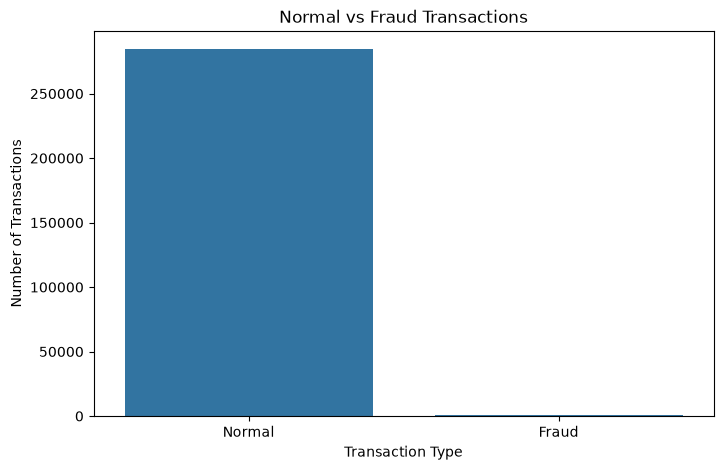

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count normal and fraud transactions
class_counts = df["Class"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=["Normal", "Fraud"],
    y=[class_counts[0], class_counts[1]]
)

plt.title("Normal vs Fraud Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()

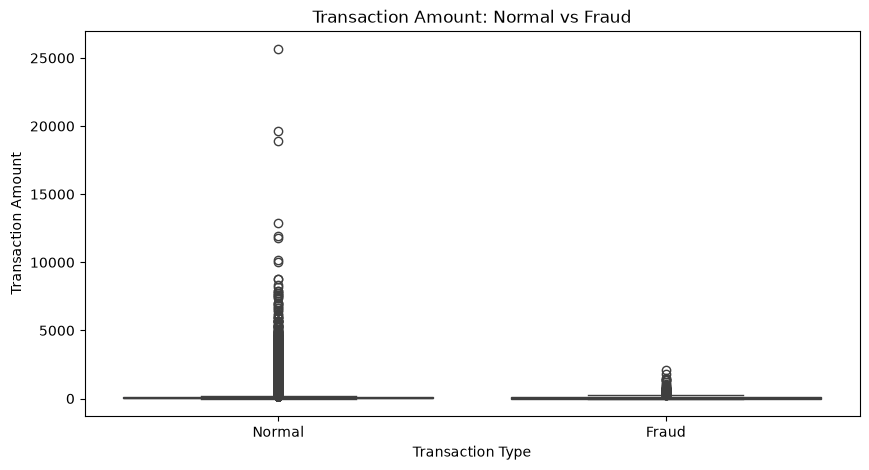

In [65]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x="Class",
    y="Amount",
    data=df
)

plt.xticks([0, 1], ["Normal", "Fraud"])
plt.title("Transaction Amount: Normal vs Fraud")
plt.xlabel("Transaction Type")
plt.ylabel("Transaction Amount")
plt.show()

In [66]:
# Convert Time from seconds to hours
df["Time_hours"] = df["Time"] / 3600

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Time_hours",
    hue="Class",
    bins=48,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Time Distribution: Normal vs Fraud")
plt.xlabel("Time (hours)")
plt.ylabel("Density")
plt.show()

KeyError: 'Time'

In [ ]:
print(df.columns.tolist())

['zTime', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


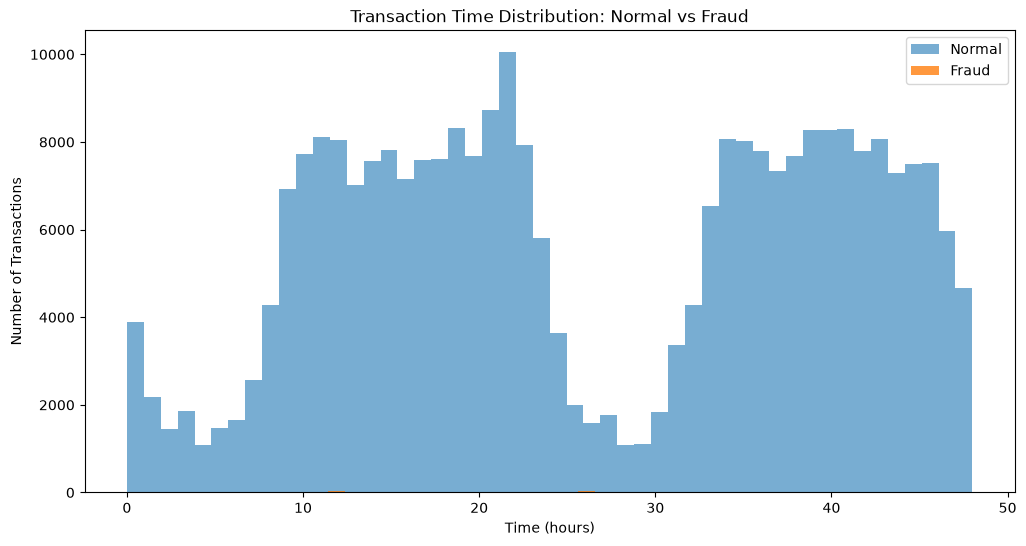

In [ ]:
import matplotlib.pyplot as plt

# Convert transaction time from seconds to hours
df["Time_Hours"] = df["zTime"] / 3600

# Separate normal and fraud transactions
normal = df[df["Class"] == 0]
fraud = df[df["Class"] == 1]

plt.figure(figsize=(12, 6))

plt.hist(normal["Time_Hours"], bins=50, alpha=0.6, label="Normal")
plt.hist(fraud["Time_Hours"], bins=50, alpha=0.8, label="Fraud")

plt.title("Transaction Time Distribution: Normal vs Fraud")
plt.xlabel("Time (hours)")
plt.ylabel("Number of Transactions")
plt.legend()
plt.show()

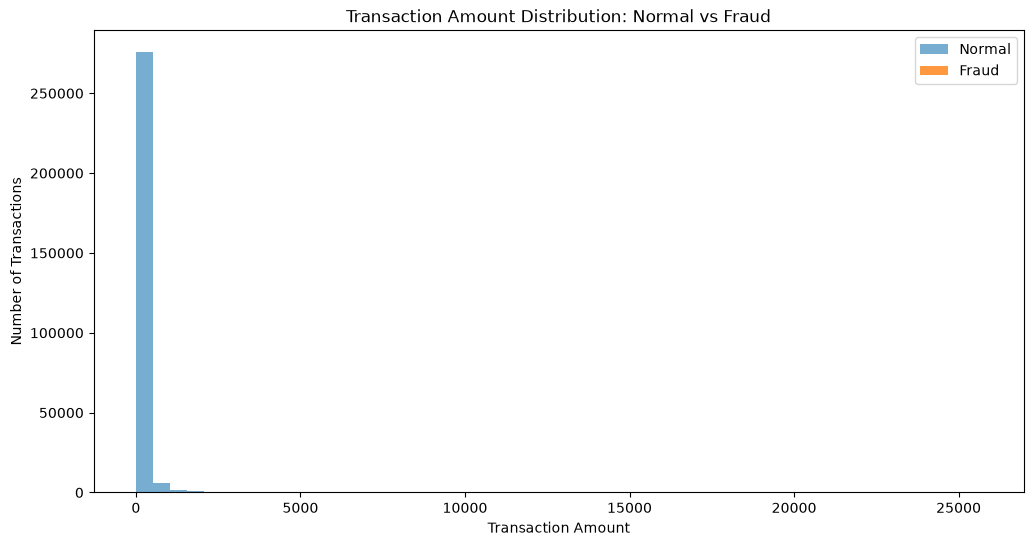

In [ ]:
plt.figure(figsize=(12, 6))

plt.hist(normal["Amount"], bins=50, alpha=0.6, label="Normal")
plt.hist(fraud["Amount"], bins=50, alpha=0.8, label="Fraud")

plt.title("Transaction Amount Distribution: Normal vs Fraud")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.legend()

plt.show()


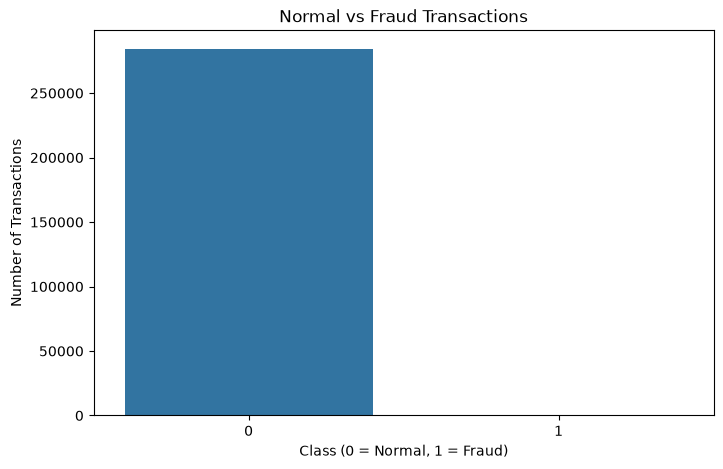

Normal Transactions: 284315
Fraud Transactions: 492


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.countplot(x="Class", data=df)

plt.title("Normal vs Fraud Transactions")
plt.xlabel("Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

print("Normal Transactions:", (df["Class"] == 0).sum())
print("Fraud Transactions:", (df["Class"] == 1).sum())

In [ ]:
# Correlation of features with fraud class

correlation = df.corr(numeric_only=True)["Class"].sort_values()

print("Features most negatively correlated with fraud:")
print(correlation.head(10))

print("\nFeatures most positively correlated with fraud:")
print(correlation.tail(10))

Features most negatively correlated with fraud:
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V18   -0.111485
V1    -0.101347
V9    -0.097733
Name: Class, dtype: float64

Features most positively correlated with fraud:
V28      0.009536
V27      0.017580
V8       0.019875
V20      0.020090
V19      0.034783
V21      0.040413
V2       0.091289
V4       0.133447
V11      0.154876
Class    1.000000
Name: Class, dtype: float64


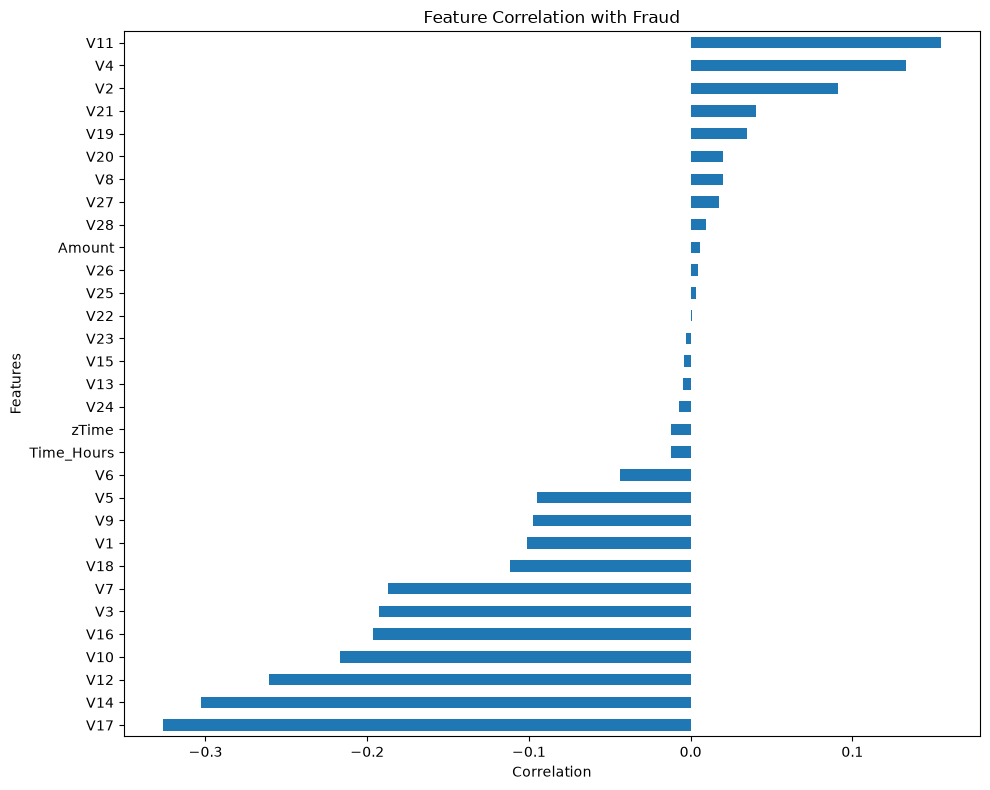

In [ ]:
plt.figure(figsize=(10, 8))

correlation.drop("Class").sort_values().plot(kind="barh")

plt.title("Feature Correlation with Fraud")
plt.xlabel("Correlation")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

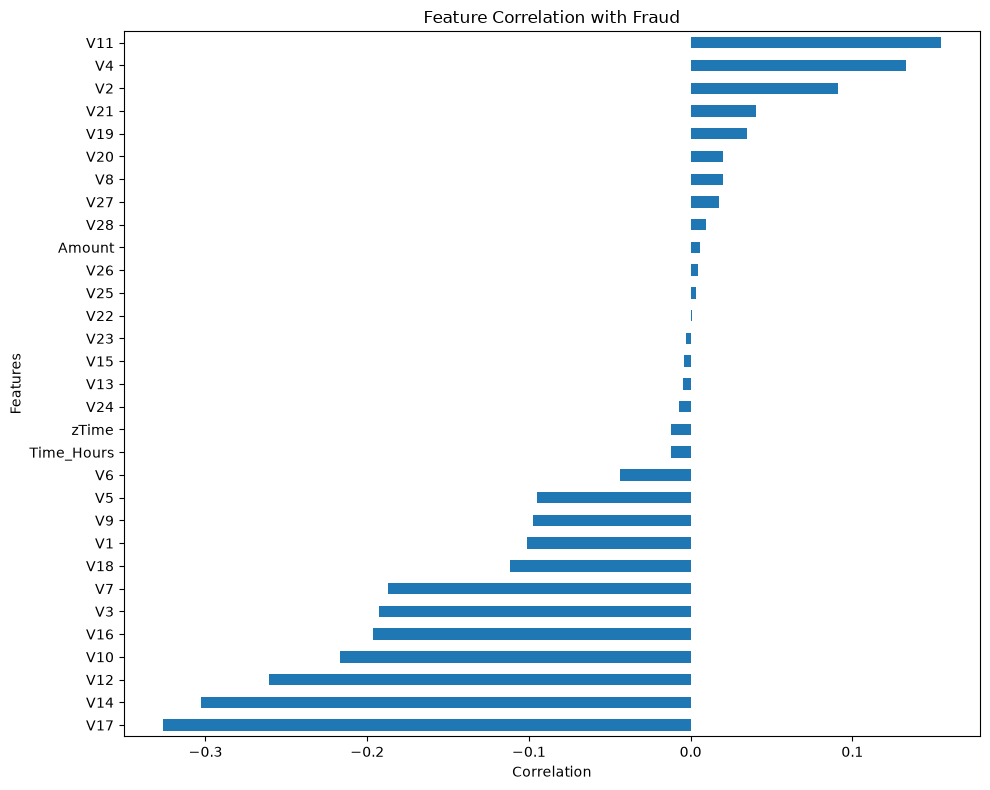

In [ ]:
plt.figure(figsize=(10, 8))

correlation.drop("Class").sort_values().plot(kind="barh")

plt.title("Feature Correlation with Fraud")
plt.xlabel("Correlation")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [ ]:
# ==============================
# DATA QUALITY CHECK
# ==============================

print("Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes.value_counts())

Missing Values:
0

Duplicate Rows:
1081

Dataset Shape:
(284807, 32)

Data Types:
float64    31
int64       1
Name: count, dtype: int64


In [ ]:
# ==========================================
# TIME-AWARE TRAIN / VALIDATION / TEST SPLIT
# ==========================================

# Sort transactions by transaction time
df = df.sort_values("zTime").reset_index(drop=True)

# 70% Training
# 15% Validation
# 15% Testing

train_end = int(len(df) * 0.70)
val_end = int(len(df) * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Training Shape:", train_df.shape)
print("Validation Shape:", val_df.shape)
print("Testing Shape:", test_df.shape)

print("\nFraud Count:")
print("Train:", train_df["Class"].sum())
print("Validation:", val_df["Class"].sum())
print("Test:", test_df["Class"].sum())

Training Shape: (199364, 32)
Validation Shape: (42721, 32)
Testing Shape: (42722, 32)

Fraud Count:
Train: 384
Validation: 56
Test: 52


In [ ]:
# ==========================================
# FEATURE PREPROCESSING & SCALING
# ==========================================

from sklearn.preprocessing import StandardScaler

# Target column
target = "Class"

# Features
feature_columns = [col for col in df.columns if col not in [target, "Time_Hours"]]

# Separate features and target
X_train = train_df[feature_columns]
y_train = train_df[target]

X_val = val_df[feature_columns]
y_val = val_df[target]

X_test = test_df[feature_columns]
y_test = test_df[target]

# Use ONLY normal transactions to learn normal behavior
X_train_normal = X_train[y_train == 0]

# Create scaler
scaler = StandardScaler()

# Fit scaler only on normal training data
X_train_normal_scaled = scaler.fit_transform(X_train_normal)

# Transform validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Total Features:", len(feature_columns))
print("Normal Training Samples:", X_train_normal.shape[0])
print("Validation Samples:", X_val.shape[0])
print("Test Samples:", X_test.shape[0])

print("\nScaled Training Shape:", X_train_normal_scaled.shape)
print("Scaled Validation Shape:", X_val_scaled.shape)
print("Scaled Test Shape:", X_test_scaled.shape)

Total Features: 30
Normal Training Samples: 198980
Validation Samples: 42721
Test Samples: 42722

Scaled Training Shape: (198980, 30)
Scaled Validation Shape: (42721, 30)
Scaled Test Shape: (42722, 30)


In [ ]:
# ==========================================
# ISOLATION FOREST
# ==========================================

from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

# Create Isolation Forest model
isolation_forest = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

# Train only on normal transactions
isolation_forest.fit(X_train_normal_scaled)

print("Isolation Forest training completed!")

Isolation Forest training completed!


In [ ]:
# ==========================================
# ISOLATION FOREST PREDICTION
# ==========================================

# Raw predictions
val_if_prediction = isolation_forest.predict(X_val_scaled)
test_if_prediction = isolation_forest.predict(X_test_scaled)

# Convert: -1 = anomaly → 1, normal → 0
val_if_anomaly = (val_if_prediction == -1).astype(int)
test_if_anomaly = (test_if_prediction == -1).astype(int)

# Anomaly scores
# Higher value = more anomalous
val_if_score = -isolation_forest.score_samples(X_val_scaled)
test_if_score = -isolation_forest.score_samples(X_test_scaled)

print("Validation anomalies detected:", val_if_anomaly.sum())
print("Test anomalies detected:", test_if_anomaly.sum())

print("\nValidation score range:",
      val_if_score.min(), "to", val_if_score.max())

print("Test score range:",
      test_if_score.min(), "to", test_if_score.max())

Validation anomalies detected: 2401
Test anomalies detected: 1812

Validation score range: 0.3650608271196321 to 0.751618986853772
Test score range: 0.36564404202550904 to 0.7656572652112643


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Isolation Forest predictions
y_true = y_test
y_pred = test_if_anomaly

print("========== ISOLATION FOREST RESULTS ==========\n")

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall:", recall_score(y_true, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_true, y_pred, zero_division=0))
print("PR-AUC:", average_precision_score(y_true, test_if_score))

========== ISOLATION FOREST RESULTS ==========

Confusion Matrix:
[[40898  1772]
 [   12    40]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.96      0.98     42670
       Fraud       0.02      0.77      0.04        52

    accuracy                           0.96     42722
   macro avg       0.51      0.86      0.51     42722
weighted avg       1.00      0.96      0.98     42722

Precision: 0.02207505518763797
Recall: 0.7692307692307693
F1 Score: 0.04291845493562232
PR-AUC: 0.031319963047192256


In [ ]:
# ==========================================
# LOCAL OUTLIER FACTOR (LOF)
# ==========================================

from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto",
    novelty=True,
    n_jobs=-1
)

# Train only on normal training transactions
lof.fit(X_train_normal_scaled)

print("LOF training completed!")

LOF training completed!


In [ ]:
# ==========================================
# LOF PREDICTION
# ==========================================

# Raw predictions
val_lof_prediction = lof.predict(X_val_scaled)
test_lof_prediction = lof.predict(X_test_scaled)

# Convert: -1 = anomaly → 1, normal → 0
val_lof_anomaly = (val_lof_prediction == -1).astype(int)
test_lof_anomaly = (test_lof_prediction == -1).astype(int)

# LOF decision score
# Lower decision_function = more anomalous
val_lof_score = -lof.decision_function(X_val_scaled)
test_lof_score = -lof.decision_function(X_test_scaled)

print("Validation anomalies detected:", val_lof_anomaly.sum())
print("Test anomalies detected:", test_lof_anomaly.sum())

print("\nValidation score range:",
      val_lof_score.min(), "to", val_lof_score.max())

print("Test score range:",
      test_lof_score.min(), "to", test_lof_score.max())

Validation anomalies detected: 5497
Test anomalies detected: 12024

Validation score range: -0.5625185716577249 to 352.20001356665864
Test score range: -0.5544968915147971 to 123.84408084232837


In [ ]:
# ==========================================
# LOF EVALUATION
# ==========================================

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

y_true = y_test
y_pred = test_lof_anomaly

print("========== LOF RESULTS ==========\n")

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall:", recall_score(y_true, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_true, y_pred, zero_division=0))
print("PR-AUC:", average_precision_score(y_true, test_lof_score))

========== LOF RESULTS ==========

Confusion Matrix:
[[30661 12009]
 [   37    15]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.72      0.84     42670
       Fraud       0.00      0.29      0.00        52

    accuracy                           0.72     42722
   macro avg       0.50      0.50      0.42     42722
weighted avg       1.00      0.72      0.83     42722

Precision: 0.00124750499001996
Recall: 0.28846153846153844
F1 Score: 0.002484266313348791
PR-AUC: 0.0014778765954845615


In [ ]:
# ==========================================
# ONE-CLASS SVM
# ==========================================

from sklearn.svm import OneClassSVM

# Use a subset of normal training data
svm_sample_size = min(50000, len(X_train_normal_scaled))

X_svm_train = X_train_normal_scaled[:svm_sample_size]

print("One-Class SVM training samples:", len(X_svm_train))

one_class_svm = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.01
)

one_class_svm.fit(X_svm_train)

print("One-Class SVM training completed!")

One-Class SVM training samples: 50000
One-Class SVM training completed!


In [ ]:
# ==========================================
# ONE-CLASS SVM PREDICTION
# ==========================================

# Predictions
val_svm_prediction = one_class_svm.predict(X_val_scaled)
test_svm_prediction = one_class_svm.predict(X_test_scaled)

# Convert: -1 = anomaly -> 1, normal -> 0
val_svm_anomaly = (val_svm_prediction == -1).astype(int)
test_svm_anomaly = (test_svm_prediction == -1).astype(int)

# Anomaly score
# Higher value = more anomalous
val_svm_score = -one_class_svm.decision_function(X_val_scaled)
test_svm_score = -one_class_svm.decision_function(X_test_scaled)

print("Validation anomalies detected:", val_svm_anomaly.sum())
print("Test anomalies detected:", test_svm_anomaly.sum())

print("\nValidation score range:",
      val_svm_score.min(), "to", val_svm_score.max())

print("Test score range:",
      test_svm_score.min(), "to", test_svm_score.max())

Validation anomalies detected: 9438
Test anomalies detected: 13552

Validation score range: -1.6898971536490404 to 1.96547935027231
Test score range: -1.2345818332215495 to 1.96547935027231


In [ ]:
# ==========================================
# ONE-CLASS SVM EVALUATION
# ==========================================

y_true = y_test
y_pred = test_svm_anomaly

print("========== ONE-CLASS SVM RESULTS ==========\n")

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall:", recall_score(y_true, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_true, y_pred, zero_division=0))
print("PR-AUC:", average_precision_score(y_true, test_svm_score))

========== ONE-CLASS SVM RESULTS ==========

Confusion Matrix:
[[29166 13504]
 [    4    48]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.68      0.81     42670
       Fraud       0.00      0.92      0.01        52

    accuracy                           0.68     42722
   macro avg       0.50      0.80      0.41     42722
weighted avg       1.00      0.68      0.81     42722

Precision: 0.0035419126328217238
Recall: 0.9230769230769231
F1 Score: 0.007056748015289621
PR-AUC: 0.15907896722270748


In [ ]:
# ==========================================
# AUTOENCODER - ANOMALY DETECTION
# ==========================================

import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow Version:", tf.__version__)

# Input dimension
input_dim = X_train_scaled.shape[1]

# Build Autoencoder
autoencoder = models.Sequential([
    layers.Input(shape=(input_dim,)),

    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),

    layers.Dense(16, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(input_dim, activation="linear")
])

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

TensorFlow Version: 2.21.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 30)             │           990 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,334 (13.02 KB)

 Trainable params: 3,334 (13.02 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==========================================
# PREPARE SCALED DATA FOR AUTOENCODER
# ==========================================

from sklearn.preprocessing import StandardScaler

scaler_autoencoder = StandardScaler()

X_train_scaled = scaler_autoencoder.fit_transform(X_train)
X_val_scaled = scaler_autoencoder.transform(X_val)
X_test_scaled = scaler_autoencoder.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Validation data shape:", X_val_scaled.shape)
print("Test data shape:", X_test_scaled.shape)
input_dim = X_train_scaled.shape[1]

Training data shape: (199364, 30)
Validation data shape: (42721, 30)
Test data shape: (42722, 30)


In [ ]:
# ==========================================
# TRAIN AUTOENCODER
# ==========================================

history = autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=20,
    batch_size=256,
    validation_data=(X_val_scaled, X_val_scaled),
    shuffle=True,
    verbose=1
)

print("Autoencoder training completed!")

Epoch 1/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.6959 - val_loss: 0.6934
Epoch 2/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.4741 - val_loss: 0.5867
Epoch 3/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.4163 - val_loss: 0.5399
Epoch 4/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.3841 - val_loss: 0.5013
Epoch 5/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3619 - val_loss: 0.4864
Epoch 6/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3470 - val_loss: 0.4625
Epoch 7/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.3370 - val_loss: 0.4585
Epoch 8/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3287 - val_loss: 0.4602
Epoch 9/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3201 - val_loss: 0.4453
Epoch 10/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.3136 - val_loss: 0.4367
Epoch 11/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.3081 - val_loss: 0.4327
Epoch 12/20
779/779 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step

In [ ]:
# ==========================================
# AUTOENCODER RECONSTRUCTION ERROR
# ==========================================

import numpy as np

# Reconstruct validation and test data
val_reconstructed = autoencoder.predict(
    X_val_scaled,
    verbose=0
)

test_reconstructed = autoencoder.predict(
    X_test_scaled,
    verbose=0
)

# Mean Squared Reconstruction Error
val_ae_score = np.mean(
    np.square(X_val_scaled - val_reconstructed),
    axis=1
)

test_ae_score = np.mean(
    np.square(X_test_scaled - test_reconstructed),
    axis=1
)

print("Validation AE score range:",
      val_ae_score.min(), "to", val_ae_score.max())

print("Test AE score range:",
      test_ae_score.min(), "to", test_ae_score.max())

print("Validation mean AE score:",
      val_ae_score.mean())

print("Test mean AE score:",
      test_ae_score.mean())

Validation AE score range: 0.016777296065807804 to 102.05410126123964
Test AE score range: 0.03335090387863794 to 72.86886765990867
Validation mean AE score: 0.36990435952414547
Test mean AE score: 0.3739784248124008


In [ ]:
# ==========================================
# HYBRID ANOMALY SCORE
# ==========================================

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Combine validation scores
val_scores = np.column_stack([
    val_if_score,
    val_lof_score,
    val_svm_score,
    val_ae_score
])

# Combine test scores
test_scores = np.column_stack([
    test_if_score,
    test_lof_score,
    test_svm_score,
    test_ae_score
])

# Scale all model scores to 0-1
hybrid_scaler = MinMaxScaler()

val_scores_scaled = hybrid_scaler.fit_transform(val_scores)
test_scores_scaled = hybrid_scaler.transform(test_scores)

# Model weights
IF_WEIGHT = 0.25
LOF_WEIGHT = 0.25
SVM_WEIGHT = 0.20
AE_WEIGHT = 0.30

# Hybrid anomaly score
val_hybrid_score = (
    IF_WEIGHT * val_scores_scaled[:, 0] +
    LOF_WEIGHT * val_scores_scaled[:, 1] +
    SVM_WEIGHT * val_scores_scaled[:, 2] +
    AE_WEIGHT * val_scores_scaled[:, 3]
)

test_hybrid_score = (
    IF_WEIGHT * test_scores_scaled[:, 0] +
    LOF_WEIGHT * test_scores_scaled[:, 1] +
    SVM_WEIGHT * test_scores_scaled[:, 2] +
    AE_WEIGHT * test_scores_scaled[:, 3]
)

print("Hybrid Anomaly Engine Created!")
print()
print("Validation Hybrid Score:")
print("Min:", val_hybrid_score.min())
print("Max:", val_hybrid_score.max())
print("Mean:", val_hybrid_score.mean())

print()
print("Test Hybrid Score:")
print("Min:", test_hybrid_score.min())
print("Max:", test_hybrid_score.max())
print("Mean:", test_hybrid_score.mean())

Hybrid Anomaly Engine Created!

Validation Hybrid Score:
Min: 0.009986403407716013
Max: 0.7298759903368344
Mean: 0.11135229601721233

Test Hybrid Score:
Min: 0.03570081472541607
Max: 0.678226157620462
Mean: 0.12017785915201892


In [ ]:
# ==========================================
# CHECK HYBRID SCORE BEHAVIOR
# ==========================================

normal_mean = val_hybrid_score[y_val.values == 0].mean()
fraud_mean = val_hybrid_score[y_val.values == 1].mean()

print("Normal transaction mean score:", normal_mean)
print("Fraud transaction mean score:", fraud_mean)

if fraud_mean > normal_mean:
    print("\nHigher Hybrid Score = More Suspicious")
else:
    print("\nLower Hybrid Score = More Suspicious")

Normal transaction mean score: 0.11109709599045338
Fraud transaction mean score: 0.3057828164042011

Higher Hybrid Score = More Suspicious


In [ ]:
# ==========================================
# HYBRID RISK SCORE: 0 - 100
# ==========================================

# Convert hybrid anomaly score into percentage risk score
val_risk_score = val_hybrid_score * 100
test_risk_score = test_hybrid_score * 100

# Keep scores strictly between 0 and 100
val_risk_score = np.clip(val_risk_score, 0, 100)
test_risk_score = np.clip(test_risk_score, 0, 100)

print("Validation Risk Score:")
print("Min:", val_risk_score.min())
print("Max:", val_risk_score.max())
print("Mean:", val_risk_score.mean())

print("\nTest Risk Score:")
print("Min:", test_risk_score.min())
print("Max:", test_risk_score.max())
print("Mean:", test_risk_score.mean())

Validation Risk Score:
Min: 0.9986403407716014
Max: 72.98759903368344
Mean: 11.135229601721234

Test Risk Score:
Min: 3.5700814725416072
Max: 67.8226157620462
Mean: 12.017785915201893


In [ ]:
# ==========================================
# THRESHOLD CALIBRATION USING VALIDATION DATA
# ==========================================

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

# Actual validation labels
y_val_array = np.asarray(y_val)

# Precision-Recall curve
precision, recall, thresholds = precision_recall_curve(
    y_val_array,
    val_risk_score
)

# Calculate F1 for every threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Best threshold based on validation F1
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best Validation Threshold:", best_threshold)
print("Best Validation Precision:", precision[best_index])
print("Best Validation Recall:", recall[best_index])
print("Best Validation F1:", f1_scores[best_index])

# Predictions using calibrated threshold
val_pred = (val_risk_score >= best_threshold).astype(int)

print("\nValidation Metrics at Calibrated Threshold:")
print("Precision:", precision_score(y_val_array, val_pred))
print("Recall:", recall_score(y_val_array, val_pred))
print("F1 Score:", f1_score(y_val_array, val_pred))

Best Validation Threshold: 33.004216649057994
Best Validation Precision: 0.0784313725490196
Best Validation Recall: 0.5
Best Validation F1: 0.13559322031554152

Validation Metrics at Calibrated Threshold:
Precision: 0.0784313725490196
Recall: 0.5
F1 Score: 0.13559322033898305


In [ ]:
# ==========================================
# FINAL TEST SET EVALUATION
# ==========================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

# Use the threshold learned from validation data
test_pred = (test_risk_score >= best_threshold).astype(int)

# Test metrics
test_precision = precision_score(y_test, test_pred, zero_division=0)
test_recall = recall_score(y_test, test_pred, zero_division=0)
test_f1 = f1_score(y_test, test_pred, zero_division=0)
test_pr_auc = average_precision_score(y_test, test_risk_score)
test_roc_auc = roc_auc_score(y_test, test_risk_score)

print("========================================")
print("FINAL TEST SET EVALUATION")
print("========================================")

print("\nPrecision :", test_precision)
print("Recall    :", test_recall)
print("F1 Score  :", test_f1)
print("PR-AUC    :", test_pr_auc)
print("ROC-AUC   :", test_roc_auc)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

FINAL TEST SET EVALUATION

Precision : 0.11926605504587157
Recall    : 0.5
F1 Score  : 0.1925925925925926
PR-AUC    : 0.0732852816687619
ROC-AUC   : 0.9387265417966144

Confusion Matrix:
[[42478   192]
 [   26    26]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     42670
       Fraud       0.12      0.50      0.19        52

    accuracy                           0.99     42722
   macro avg       0.56      0.75      0.60     42722
weighted avg       1.00      0.99      1.00     42722



In [ ]:
# ==========================================
# FRAUD ALERT + EXPLAINABILITY ENGINE
# ==========================================

import pandas as pd
import numpy as np

# Create test results table
test_results = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Risk_Score": test_risk_score,
    "IF_Score": test_scores_scaled[:, 0],
    "LOF_Score": test_scores_scaled[:, 1],
    "SVM_Score": test_scores_scaled[:, 2],
    "AE_Score": test_scores_scaled[:, 3],
    "Prediction": test_pred
})

# Risk level
def get_risk_level(score):
    if score < 30:
        return "LOW"
    elif score < 70:
        return "MEDIUM"
    else:
        return "HIGH"

test_results["Risk_Level"] = test_results["Risk_Score"].apply(
    get_risk_level
)

# Generate explanation
def get_reason(row):
    scores = {
        "Isolation Forest": row["IF_Score"],
        "LOF": row["LOF_Score"],
        "One-Class SVM": row["SVM_Score"],
        "Autoencoder": row["AE_Score"]
    }

    strongest_model = max(scores, key=scores.get)

    high_models = sum(score >= 0.70 for score in scores.values())

    if high_models >= 3:
        return f"Multiple anomaly models detected unusual behavior ({high_models}/4 models)"
    elif high_models == 2:
        return f"Two anomaly models detected unusual behavior; strongest signal: {strongest_model}"
    else:
        return f"Strongest anomaly signal detected by {strongest_model}"

test_results["Explanation"] = test_results.apply(
    get_reason,
    axis=1
)

print("Fraud Alert Engine Created!")
print()
print("Total Test Transactions:", len(test_results))
print("High Risk:", (test_results["Risk_Level"] == "HIGH").sum())
print("Medium Risk:", (test_results["Risk_Level"] == "MEDIUM").sum())
print("Low Risk:", (test_results["Risk_Level"] == "LOW").sum())

print("\nSample Alerts:")
display(
    test_results[
        ["Risk_Score", "Risk_Level", "Prediction", "Explanation"]
    ].head(10)
)

Fraud Alert Engine Created!

Total Test Transactions: 42722
High Risk: 0
Medium Risk: 418
Low Risk: 42304

Sample Alerts:


,Risk_Score,Risk_Level,Prediction,Explanation
0,10.426171,LOW,0,Strongest anomaly signal detected by One-Class...
1,6.867744,LOW,0,Strongest anomaly signal detected by One-Class...
2,6.214182,LOW,0,Strongest anomaly signal detected by One-Class...
3,7.347460,LOW,0,Strongest anomaly signal detected by One-Class...
4,14.750313,LOW,0,Strongest anomaly signal detected by One-Class...
5,8.175038,LOW,0,Strongest anomaly signal detected by One-Class...
6,6.150563,LOW,0,Strongest anomaly signal detected by One-Class...
7,8.930392,LOW,0,Strongest anomaly signal detected by One-Class...
8,9.199826,LOW,0,Strongest anomaly signal detected by One-Class...
9,11.866371,LOW,0,Strongest anomaly signal detected by One-Class...


In [ ]:
# Check trained model variables

model_candidates = [
    "isolation_forest",
    "lof",
    "ocsvm",
    "autoencoder",
    "scaler",
    "scaler_autoencoder"
]

for name in model_candidates:
    if name in globals():
        print(f"✅ {name} found")
    else:
        print(f"❌ {name} not found")

✅ isolation_forest found
✅ lof found
❌ ocsvm not found
✅ autoencoder found
✅ scaler found
✅ scaler_autoencoder found


In [ ]:
import joblib
import os

# Models folder
os.makedirs("../models", exist_ok=True)

# Save Scikit-learn models
joblib.dump(isolation_forest, "../models/isolation_forest.pkl")
joblib.dump(lof, "../models/lof.pkl")
joblib.dump(one_class_svm, "../models/one_class_svm.pkl")

# Save scalers
joblib.dump(scaler, "../models/scaler.pkl")
joblib.dump(scaler_autoencoder, "../models/scaler_autoencoder.pkl")

# Save Autoencoder
autoencoder.save("../models/autoencoder.keras")

print("✅ All models and scalers saved successfully!")

✅ All models and scalers saved successfully!


In [3]:
import joblib
import json
import os

# Save hybrid scaler
joblib.dump(
    hybrid_scaler,
    "../models/hybrid_scaler.pkl"
)

# Save calibrated threshold
with open("../models/threshold.json", "w") as f:
    json.dump(
        {
            "best_threshold": float(best_threshold),
            "IF_WEIGHT": 0.25,
            "LOF_WEIGHT": 0.25,
            "SVM_WEIGHT": 0.20,
            "AE_WEIGHT": 0.30
        },
        f,
        indent=4
    )

print("✅ Hybrid scaler saved")
print("✅ Threshold saved")
print("✅ Configuration saved")

NameError: name 'hybrid_scaler' is not defined

In [4]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import precision_recall_curve
import numpy as np
import joblib
import json

# ==========================================
# CREATE HYBRID SCALER AGAIN
# ==========================================

val_scores = np.column_stack([
    val_if_score,
    val_lof_score,
    val_svm_score,
    val_ae_score
])

test_scores = np.column_stack([
    test_if_score,
    test_lof_score,
    test_svm_score,
    test_ae_score
])

hybrid_scaler = MinMaxScaler()

val_scores_scaled = hybrid_scaler.fit_transform(val_scores)
test_scores_scaled = hybrid_scaler.transform(test_scores)

# ==========================================
# HYBRID SCORE
# ==========================================

val_hybrid_score = (
    0.25 * val_scores_scaled[:, 0] +
    0.25 * val_scores_scaled[:, 1] +
    0.20 * val_scores_scaled[:, 2] +
    0.30 * val_scores_scaled[:, 3]
)

test_hybrid_score = (
    0.25 * test_scores_scaled[:, 0] +
    0.25 * test_scores_scaled[:, 1] +
    0.20 * test_scores_scaled[:, 2] +
    0.30 * test_scores_scaled[:, 3]
)

# ==========================================
# RISK SCORE
# ==========================================

val_risk_score = np.clip(val_hybrid_score * 100, 0, 100)
test_risk_score = np.clip(test_hybrid_score * 100, 0, 100)

# ==========================================
# FIND THRESHOLD FROM VALIDATION DATA
# ==========================================

y_val_array = np.asarray(y_val)

precision, recall, thresholds = precision_recall_curve(
    y_val_array,
    val_risk_score
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = float(thresholds[best_index])

# ==========================================
# SAVE EVERYTHING
# ==========================================

joblib.dump(
    hybrid_scaler,
    "../models/hybrid_scaler.pkl"
)

with open("../models/threshold.json", "w") as f:
    json.dump(
        {
            "best_threshold": best_threshold,
            "IF_WEIGHT": 0.25,
            "LOF_WEIGHT": 0.25,
            "SVM_WEIGHT": 0.20,
            "AE_WEIGHT": 0.30
        },
        f,
        indent=4
    )

print("====================================")
print("✅ Hybrid scaler created")
print("✅ Hybrid score calculated")
print("✅ Risk score calculated")
print("✅ Threshold calculated")
print("✅ Hybrid scaler saved")
print("✅ Threshold configuration saved")
print("Best threshold:", best_threshold)
print("====================================")

NameError: name 'val_if_score' is not defined

In [5]:
# ==========================================
# RECOVER PROJECT ML STATE
# ==========================================

import pandas as pd
import numpy as np
import joblib
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import precision_recall_curve

print("Loading dataset and saved models...")

# -------------------------------
# 1. Load dataset
# -------------------------------

df = pd.read_csv("../data/raw/creditcard.csv")

df = df.sort_values("zTime").reset_index(drop=True)

# -------------------------------
# 2. Time-based split
# -------------------------------

train_end = int(len(df) * 0.70)
val_end = int(len(df) * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

# -------------------------------
# 3. Features
# -------------------------------

target = "Class"

feature_columns = [
    col for col in df.columns
    if col not in [target, "Time_Hours"]
]

X_train = train_df[feature_columns]
y_train = train_df[target]

X_val = val_df[feature_columns]
y_val = val_df[target]

X_test = test_df[feature_columns]
y_test = test_df[target]

# -------------------------------
# 4. Load saved scalers
# -------------------------------

scaler = joblib.load("../models/scaler.pkl")

scaler_autoencoder = joblib.load(
    "../models/scaler_autoencoder.pkl"
)

# -------------------------------
# 5. Scale data
# -------------------------------

X_train_normal = X_train[y_train == 0]

X_train_normal_scaled = scaler.transform(X_train_normal)

X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = scaler_autoencoder.transform(X_train)
X_val_ae_scaled = scaler_autoencoder.transform(X_val)
X_test_ae_scaled = scaler_autoencoder.transform(X_test)

# -------------------------------
# 6. Load ML models
# -------------------------------

isolation_forest = joblib.load(
    "../models/isolation_forest.pkl"
)

lof = joblib.load(
    "../models/lof.pkl"
)

one_class_svm = joblib.load(
    "../models/one_class_svm.pkl"
)

autoencoder = tf.keras.models.load_model(
    "../models/autoencoder.keras"
)

print("✅ All models loaded")

# -------------------------------
# 7. Isolation Forest scores
# -------------------------------

val_if_prediction = isolation_forest.predict(X_val_scaled)
test_if_prediction = isolation_forest.predict(X_test_scaled)

val_if_anomaly = (val_if_prediction == -1).astype(int)
test_if_anomaly = (test_if_prediction == -1).astype(int)

val_if_score = -isolation_forest.score_samples(
    X_val_scaled
)

test_if_score = -isolation_forest.score_samples(
    X_test_scaled
)

# -------------------------------
# 8. LOF scores
# -------------------------------

val_lof_prediction = lof.predict(X_val_scaled)
test_lof_prediction = lof.predict(X_test_scaled)

val_lof_anomaly = (val_lof_prediction == -1).astype(int)
test_lof_anomaly = (test_lof_prediction == -1).astype(int)

val_lof_score = -lof.decision_function(
    X_val_scaled
)

test_lof_score = -lof.decision_function(
    X_test_scaled
)

# -------------------------------
# 9. One-Class SVM scores
# -------------------------------

val_svm_prediction = one_class_svm.predict(
    X_val_scaled
)

test_svm_prediction = one_class_svm.predict(
    X_test_scaled
)

val_svm_anomaly = (
    val_svm_prediction == -1
).astype(int)

test_svm_anomaly = (
    test_svm_prediction == -1
).astype(int)

val_svm_score = -one_class_svm.decision_function(
    X_val_scaled
)

test_svm_score = -one_class_svm.decision_function(
    X_test_scaled
)

# -------------------------------
# 10. Autoencoder scores
# -------------------------------

val_reconstructed = autoencoder.predict(
    X_val_ae_scaled,
    verbose=0
)

test_reconstructed = autoencoder.predict(
    X_test_ae_scaled,
    verbose=0
)

val_ae_score = np.mean(
    np.square(
        X_val_ae_scaled - val_reconstructed
    ),
    axis=1
)

test_ae_score = np.mean(
    np.square(
        X_test_ae_scaled - test_reconstructed
    ),
    axis=1
)

# -------------------------------
# 11. Hybrid scaler
# -------------------------------

val_scores = np.column_stack([
    val_if_score,
    val_lof_score,
    val_svm_score,
    val_ae_score
])

test_scores = np.column_stack([
    test_if_score,
    test_lof_score,
    test_svm_score,
    test_ae_score
])

hybrid_scaler = MinMaxScaler()

val_scores_scaled = hybrid_scaler.fit_transform(
    val_scores
)

test_scores_scaled = hybrid_scaler.transform(
    test_scores
)

# -------------------------------
# 12. Hybrid score
# -------------------------------

val_hybrid_score = (
    0.25 * val_scores_scaled[:, 0] +
    0.25 * val_scores_scaled[:, 1] +
    0.20 * val_scores_scaled[:, 2] +
    0.30 * val_scores_scaled[:, 3]
)

test_hybrid_score = (
    0.25 * test_scores_scaled[:, 0] +
    0.25 * test_scores_scaled[:, 1] +
    0.20 * test_scores_scaled[:, 2] +
    0.30 * test_scores_scaled[:, 3]
)

# -------------------------------
# 13. Risk score
# -------------------------------

val_risk_score = np.clip(
    val_hybrid_score * 100,
    0,
    100
)

test_risk_score = np.clip(
    test_hybrid_score * 100,
    0,
    100
)

# -------------------------------
# 14. Find threshold
# -------------------------------

precision, recall, thresholds = precision_recall_curve(
    np.asarray(y_val),
    val_risk_score
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    /
    (
        precision[:-1]
        + recall[:-1]
        + 1e-10
    )
)

best_index = np.argmax(f1_scores)

best_threshold = float(
    thresholds[best_index]
)

# -------------------------------
# 15. Save recovered hybrid scaler
# -------------------------------

joblib.dump(
    hybrid_scaler,
    "../models/hybrid_scaler.pkl"
)

# -------------------------------
# 16. Save threshold
# -------------------------------

import json

with open("../models/threshold.json", "w") as f:
    json.dump(
        {
            "best_threshold": best_threshold,
            "IF_WEIGHT": 0.25,
            "LOF_WEIGHT": 0.25,
            "SVM_WEIGHT": 0.20,
            "AE_WEIGHT": 0.30
        },
        f,
        indent=4
    )

print()
print("========================================")
print("✅ PROJECT STATE RECOVERED")
print("========================================")
print("Dataset:", df.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Isolation Forest: ✅")
print("LOF:               ✅")
print("One-Class SVM:     ✅")
print("Autoencoder:       ✅")
print("Hybrid Score:      ✅")
print("Risk Score:        ✅")
print("Threshold:", best_threshold)
print("========================================")

Loading dataset and saved models...
✅ All models loaded

✅ PROJECT STATE RECOVERED
Dataset: (284807, 31)
Validation: (42721, 30)
Testing: (42722, 30)
Isolation Forest: ✅
LOF:               ✅
One-Class SVM:     ✅
Autoencoder:       ✅
Hybrid Score:      ✅
Risk Score:        ✅
Threshold: 33.004216649057994


In [1]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("Available variables:")
for name in ["y_test", "y_val", "test_df", "df_test", "X_test", "X_test_scaled"]:
    if name in globals():
        print(name, "available", globals()[name].shape if hasattr(globals()[name], "shape") else "")

Available variables:


In [3]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("Available variables:")

for name in [
    "y_test", "y_val", "test_df", "df_test",
    "X_test", "X_test_scaled"
]:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            "available",
            getattr(obj, "shape", "")
        )

Available variables:


In [4]:
import os
import json
import pandas as pd

print("MODEL FILES:")
for file in os.listdir("../models"):
    print(file)

print("\nTHRESHOLD:")
with open("../models/threshold.json", "r") as f:
    print(json.load(f))

print("\nDATA FILES:")
for root, dirs, files in os.walk("../data"):
    for file in files:
        print(os.path.join(root, file))

MODEL FILES:
autoencoder.keras
hybrid_scaler.pkl
isolation_forest.pkl
lof.pkl
metadata.json
one_class_svm.pkl
scaler.pkl
scaler_autoencoder.pkl
threshold.json

THRESHOLD:
{'best_threshold': 33.004216649057994, 'IF_WEIGHT': 0.25, 'LOF_WEIGHT': 0.25, 'SVM_WEIGHT': 0.2, 'AE_WEIGHT': 0.3}

DATA FILES:
../data\raw\creditcard.csv


In [5]:
import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Project paths
BASE_DIR = os.path.abspath("..")
DATA_PATH = os.path.join(BASE_DIR, "data", "raw", "creditcard.csv")
MODEL_DIR = os.path.join(BASE_DIR, "models")

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# Match the feature names used by the trained API
if "Time" in df.columns and "zTime" not in df.columns:
    df = df.rename(columns={"Time": "zTime"})

FEATURE_COLUMNS = ["zTime"] + [f"V{i}" for i in range(1, 29)] + ["Amount"]

# Check required columns
missing = [c for c in FEATURE_COLUMNS + ["Class"] if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Same chronological split: 70% train, 15% validation, 15% test
train_end = int(len(df) * 0.70)
val_end = int(len(df) * 0.85)

test_df = df.iloc[val_end:].copy()

X_test = test_df[FEATURE_COLUMNS].to_numpy(dtype=float)
y_test = test_df["Class"].to_numpy(dtype=int)

print("Test rows:", len(X_test))
print("Actual fraud cases:", int(y_test.sum()))

# Load saved models and scalers
isolation_forest = joblib.load(os.path.join(MODEL_DIR, "isolation_forest.pkl"))
lof = joblib.load(os.path.join(MODEL_DIR, "lof.pkl"))
one_class_svm = joblib.load(os.path.join(MODEL_DIR, "one_class_svm.pkl"))

scaler = joblib.load(os.path.join(MODEL_DIR, "scaler.pkl"))
scaler_autoencoder = joblib.load(os.path.join(MODEL_DIR, "scaler_autoencoder.pkl"))
hybrid_scaler = joblib.load(os.path.join(MODEL_DIR, "hybrid_scaler.pkl"))

import tensorflow as tf

autoencoder = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "autoencoder.keras")
)

with open(os.path.join(MODEL_DIR, "threshold.json"), "r") as f:
    config = json.load(f)

threshold = float(config["best_threshold"])

# Transform test data
X_scaled = scaler.transform(X_test)
X_ae_scaled = scaler_autoencoder.transform(X_test)

# Get anomaly scores
if_score = -isolation_forest.score_samples(X_scaled)
lof_score = -lof.decision_function(X_scaled)
svm_score = -one_class_svm.decision_function(X_scaled)

reconstructed = autoencoder.predict(X_ae_scaled, verbose=0)
ae_score = np.mean((X_ae_scaled - reconstructed) ** 2, axis=1)

# Hybrid score
raw_scores = np.column_stack([
    if_score,
    lof_score,
    svm_score,
    ae_score
])

scaled_scores = hybrid_scaler.transform(raw_scores)

hybrid_score = (
    0.25 * scaled_scores[:, 0]
    + 0.25 * scaled_scores[:, 1]
    + 0.20 * scaled_scores[:, 2]
    + 0.30 * scaled_scores[:, 3]
)

risk_score = np.clip(hybrid_score * 100, 0, 100)
y_pred = (risk_score >= threshold).astype(int)

# Evaluation
print("\n===== HYBRID MODEL EVALUATION =====")
print("Threshold:", threshold)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Fraud"],
    zero_division=0
))

print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

if len(np.unique(y_test)) == 2:
    print("ROC-AUC:", roc_auc_score(y_test, risk_score))
    print("Average Precision:", average_precision_score(y_test, risk_score))

Dataset shape: (284807, 31)
Columns: ['zTime', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
Test rows: 42722
Actual fraud cases: 52


c:\Users\aknot\OneDrive\Desktop\CreditCardFraudDetection\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\aknot\OneDrive\Desktop\CreditCardFraudDetection\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



===== HYBRID MODEL EVALUATION =====
Threshold: 33.004216649057994

Confusion Matrix:
[[42478   192]
 [   26    26]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     42670
       Fraud       0.12      0.50      0.19        52

    accuracy                           0.99     42722
   macro avg       0.56      0.75      0.60     42722
weighted avg       1.00      0.99      1.00     42722

Precision: 0.11926605504587157
Recall: 0.5
F1-score: 0.1925925925925926
ROC-AUC: 0.9387265417966144
Average Precision: 0.0732852816687619


In [6]:
from sklearn.metrics import precision_recall_curve
import numpy as np

# Use validation data only for threshold selection.
# Ensure val_risk_score and y_val are calculated from the
# validation split using the same hybrid scoring pipeline.

if "val_risk_score" not in globals() or "y_val" not in globals():
    print(
        "Validation scores are not available yet. "
        "We need to calculate val_risk_score and y_val "
        "from the validation split before tuning."
    )
else:
    precision, recall, thresholds = precision_recall_curve(
        y_val,
        val_risk_score
    )

    # F1 for each available threshold
    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_index = int(np.argmax(f1_scores))

    print("Best validation threshold:", thresholds[best_index])
    print("Validation precision:", precision[best_index])
    print("Validation recall:", recall[best_index])
    print("Validation F1-score:", f1_scores[best_index])

Validation scores are not available yet. We need to calculate val_risk_score and y_val from the validation split before tuning.


In [7]:
print("Validation variables check:")

for name in ["y_val", "X_val", "X_val_scaled", "val_risk_score"]:
    if name in globals():
        obj = globals()[name]
        print(name, "available", getattr(obj, "shape", ""))
    else:
        print(name, "not available")

Validation variables check:
y_val not available
X_val not available
X_val_scaled not available
val_risk_score not available


In [8]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import precision_recall_curve

# Project paths
BASE_DIR = os.path.abspath("..")
DATA_PATH = os.path.join(BASE_DIR, "data", "raw", "creditcard.csv")
MODEL_DIR = os.path.join(BASE_DIR, "models")

# Load dataset
df = pd.read_csv(DATA_PATH)

if "Time" in df.columns and "zTime" not in df.columns:
    df = df.rename(columns={"Time": "zTime"})

FEATURE_COLUMNS = (
    ["zTime"] +
    [f"V{i}" for i in range(1, 29)] +
    ["Amount"]
)

# Same chronological split
train_end = int(len(df) * 0.70)
val_end = int(len(df) * 0.85)

val_df = df.iloc[train_end:val_end].copy()

X_val = val_df[FEATURE_COLUMNS].to_numpy(dtype=float)
y_val = val_df["Class"].to_numpy(dtype=int)

# Load saved models and scalers
isolation_forest = joblib.load(
    os.path.join(MODEL_DIR, "isolation_forest.pkl")
)
lof = joblib.load(os.path.join(MODEL_DIR, "lof.pkl"))
one_class_svm = joblib.load(
    os.path.join(MODEL_DIR, "one_class_svm.pkl")
)

scaler = joblib.load(os.path.join(MODEL_DIR, "scaler.pkl"))
scaler_autoencoder = joblib.load(
    os.path.join(MODEL_DIR, "scaler_autoencoder.pkl")
)
hybrid_scaler = joblib.load(
    os.path.join(MODEL_DIR, "hybrid_scaler.pkl")
)

autoencoder = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "autoencoder.keras")
)

# Transform validation data
X_val_scaled = scaler.transform(X_val)
X_val_ae = scaler_autoencoder.transform(X_val)

# Calculate anomaly scores
if_score = -isolation_forest.score_samples(X_val_scaled)
lof_score = -lof.decision_function(X_val_scaled)
svm_score = -one_class_svm.decision_function(X_val_scaled)

reconstructed = autoencoder.predict(X_val_ae, verbose=0)

ae_score = np.mean(
    np.square(X_val_ae - reconstructed),
    axis=1
)

# Hybrid score
raw_scores = np.column_stack([
    if_score,
    lof_score,
    svm_score,
    ae_score
])

scaled_scores = hybrid_scaler.transform(raw_scores)

hybrid_score = (
    0.25 * scaled_scores[:, 0]
    + 0.25 * scaled_scores[:, 1]
    + 0.20 * scaled_scores[:, 2]
    + 0.30 * scaled_scores[:, 3]
)

val_risk_score = np.clip(hybrid_score * 100, 0, 100)

# Select threshold using validation data only
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_risk_score
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = int(np.argmax(f1_scores))

print("Validation rows:", len(y_val))
print("Actual fraud cases:", int(y_val.sum()))
print("Best validation threshold:", thresholds[best_index])
print("Validation precision:", precision[best_index])
print("Validation recall:", recall[best_index])
print("Validation F1-score:", f1_scores[best_index])

c:\Users\aknot\OneDrive\Desktop\CreditCardFraudDetection\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\aknot\OneDrive\Desktop\CreditCardFraudDetection\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Validation rows: 42721
Actual fraud cases: 56
Best validation threshold: 33.004216649057994
Validation precision: 0.0784313725490196
Validation recall: 0.5
Validation F1-score: 0.13559322033874865


In [9]:
import os
import json

results = {
    "validation_rows": int(len(y_val)),
    "actual_fraud_cases": int(y_val.sum()),
    "best_threshold": float(thresholds[best_index]),
    "precision": float(precision[best_index]),
    "recall": float(recall[best_index]),
    "f1_score": float(f1_scores[best_index]),
}

output_path = os.path.join(BASE_DIR, "models", "evaluation_results.json")

with open(output_path, "w") as f:
    json.dump(results, f, indent=4)

print("Evaluation results saved to:", output_path)
print(json.dumps(results, indent=4))

Evaluation results saved to: c:\Users\aknot\OneDrive\Desktop\CreditCardFraudDetection\models\evaluation_results.json
{
    "validation_rows": 42721,
    "actual_fraud_cases": 56,
    "best_threshold": 33.004216649057994,
    "precision": 0.0784313725490196,
    "recall": 0.5,
    "f1_score": 0.13559322033874865
}


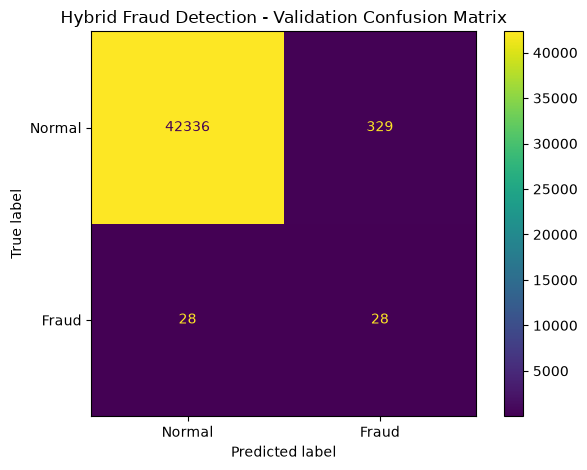

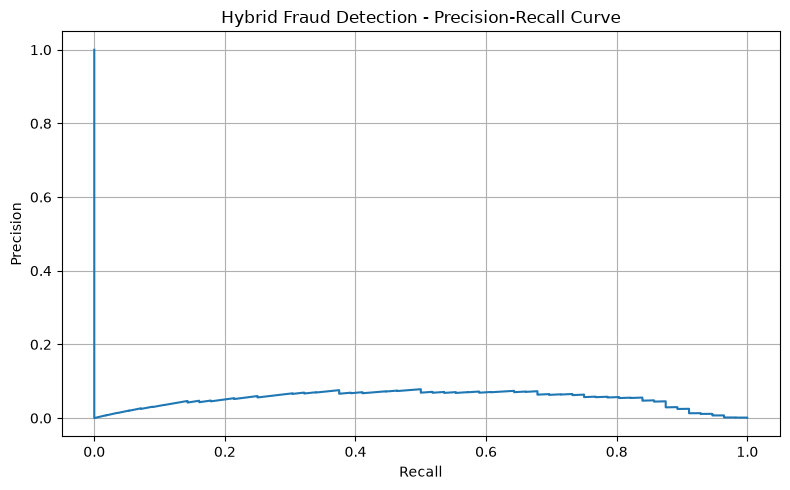

Graphs saved successfully in: c:\Users\aknot\OneDrive\Desktop\CreditCardFraudDetection\reports


In [10]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

# Output folder
output_dir = os.path.join(BASE_DIR, "reports")
os.makedirs(output_dir, exist_ok=True)

# Predictions using the selected threshold
y_pred = (val_risk_score >= thresholds[best_index]).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_val, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
)

disp.plot()
plt.title("Hybrid Fraud Detection - Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Precision-Recall Curve
precision_curve, recall_curve, _ = precision_recall_curve(
    y_val,
    val_risk_score
)

plt.figure(figsize=(8, 5))
plt.plot(recall_curve, precision_curve)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Hybrid Fraud Detection - Precision-Recall Curve")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "precision_recall_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphs saved successfully in:", output_dir)